# Machine Learning Homework - Group 22
## Notebook 02 - Clean & Preprocess  (5 pts)

**Objective.** Handle missing values and anomalous observations, integrate `clientes.csv`,
encode categorical variables, create features, and scale - reproducibly, and without ever
fitting anything on `test.csv`.

**Inputs.** `data/train_raw.csv`, `data/test_raw.csv`, `data/clientes_raw.csv` (written by Notebook 01)
**Outputs.** `data/train_clean.csv`, `data/test_clean.csv`, `data/feature_lists.csv`,
`artifacts/features/*.csv`, `artifacts/logs/cleaning_log.csv`,
`artifacts/figures/nb02_missing_before_after.png`

### Every action traces back to a Notebook 01 finding

| Notebook 01 finding | Action taken here |
|---|---|
| 65 train rows have every transaction field null; test has none | Dropped from **train only**, target balance verified before and after |
| 1e9 placeholders in Prior Mean Purchase Value and Spend (365d) | Converted to NaN + invalid-value flag. Never clipped into a real number |
| Impossible negatives in Spend (365d), Days Since Previous Purchase, Prior Mean Purchase Gap | Converted to NaN + flag |
| `prior_*` nulls are structural: 603 first-time buyers, and dispersion statistics are undefined after a single purchase | Filled 0 **only for those rows**, with `no_purchase_history` / `single_purchase` flags kept, so "no history" stays a signal instead of being buried under a median |
| Categorical nulls (~4% of rows) carry no history meaning | Imputed an explicit `Missing` level, which one-hot encodes into its own column |
| `transport_method` has 80 levels, 59 of them below 1% of rows | Levels below 1% of train grouped into `Other` before encoding |
| `clientes` attributes with <= 40 levels carry real signal (up to 38.5 pp off baseline) | Joined on `customer_id` (1:1, verified); free-text and 100%-null attributes dropped |
| Train spans 2015-2025, test 2025-2026 | `purchase_year` computed for QA but **excluded from the model** (a coefficient on a year cannot extrapolate past the training range); `purchase_month` is kept because seasonality repeats |
| 29 features with \|skew\| > 1.5 and heavy zero-inflation | `log1p` on the skewed non-negative columns before scaling |
| `random_noise` is a planted column with near-zero association | Dropped |

### Leakage policy
`SimpleImputer`, `StandardScaler` and `OneHotEncoder` are fitted on the training rows only and
then applied to test. The fitted values (medians, means, scales, kept levels, categories) are
written to `artifacts/features/`, so the transformation is auditable without a pickle file.

### Order of operations
1. Setup and cleaning log
2. Load Notebook 01 outputs and verify integrity
3. Column roles and the drop list
4. Structurally empty rows (train only)
5. Invalid values -> NaN + flags
6. Missingness mechanism audit + flags
7. Integrate `clientes`
8. Categorical cleaning (explicit Missing level, rare-level grouping)
9. Numeric imputation (train-only medians)
10. Feature engineering (month, two ratios, log1p)
11. Scaling (train-only StandardScaler)
12. Encoding (train-only OneHotEncoder)
13. Assemble and validate the model matrices
14. Before/after missingness check
15. Persist outputs and the cleaning log
16. Handover summary

**Naming note.** Unlike the exploration notebook, the tables and figures here print raw column
names on purpose: they are the literal column names written to `train_clean.csv`, and the
next notebooks select features by those keys.

### Cell 1 - Environment and cleaning log
**Purpose.** Import the toolkit, fix the paths, and open a log that records every transformation.
**Method.** The log stores step, action, columns touched, rows affected and the reason, and is
written to `artifacts/logs/cleaning_log.csv` at the end.
**Look at.** The thresholds defined here: they are the rules the rest of the notebook applies.

In [1]:
# CELL 1 - Setup: imports, paths, constants, and the cleaning log.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Notebooks run from inside 01_notebooks/, so the repo root is the parent folder.
ROOT = Path.cwd().parent
DATA_DIR = ROOT / "data"
ARTIFACTS_DIR = ROOT / "artifacts"
FIG_DIR = ARTIFACTS_DIR / "figures"
LOG_DIR = ARTIFACTS_DIR / "logs"
FEAT_DIR = ARTIFACTS_DIR / "features"

TARGET = "repeat_purchase_90d"
PLOT_BLUE = "#1779A8"
PLOT_ORANGE = "#C96A00"

SENTINEL_FLOOR = 1e8      # NB01 Cell 9: 1e9 placeholders
RARE_LEVEL_SHARE = 0.01   # categorical levels below 1% of train rows are grouped into Other
SKEW_CUTOFF = 1.5         # NB01 rule for log1p candidates
META_MAX_LEVELS = 40      # NB01 rule for an analysable clientes attribute

# Every step is recorded so the whole pipeline can be read as a table and reproduced.
CLEAN_LOG = []


def log_action(step, action, columns, rows_affected, reason):
    CLEAN_LOG.append({"step": step, "action": action, "columns": columns,
                      "rows_affected": rows_affected, "reason": reason})


def guide(ax, text):
    # Append a "how to read" caption to the axes title, so a figure still explains itself
    # when it is printed on a page or opened on its own.
    ax.set_title(ax.get_title() + "\n" + text, fontsize=9)

sns.set_theme(style="whitegrid")
print("Environment ready.")
print("  data      :", DATA_DIR)
print("  artifacts :", ARTIFACTS_DIR)

Environment ready.
  data      : C:\Users\Mohamed_Triki\Desktop\Projets\machine_learning\ML_Group_22\data
  artifacts : C:\Users\Mohamed_Triki\Desktop\Projets\machine_learning\ML_Group_22\artifacts


### Cell 2 - Load and verify
**Purpose.** Read Notebook 01's raw frames and check they are what Notebook 01 promised.
**Method.** Shapes, uniqueness of the keys, and an assertion that train and test share the same
feature names.
**Look at.** The three assertions: a failure here means the notebooks are out of sync.

In [2]:
# CELL 2 - Load the raw frames written by Notebook 01 and verify integrity.
# CSV only: pickle is not part of the course toolkit.
train = pd.read_csv(DATA_DIR / "train_raw.csv")
test = pd.read_csv(DATA_DIR / "test_raw.csv")
clientes = pd.read_csv(DATA_DIR / "clientes_raw.csv")

n_train_raw, n_test_raw = len(train), len(test)

print("=== Shapes ===")
print("  train    :", train.shape)
print("  test     :", test.shape)
print("  clientes :", clientes.shape)

print("\n=== Integrity checks ===")
print("  target in train only           :", TARGET in train.columns and TARGET not in test.columns)
print("  train ID unique                :", bool(train["ID"].nunique() == len(train)))
print("  test ID unique                 :", bool(test["ID"].nunique() == len(test)))
extra = sorted(set(test.columns) - set(train.columns))
print("  columns only in test           :", extra if extra else "none")
print("  train/test feature names match :", sorted(set(train.columns) - {TARGET}) == sorted(set(test.columns)))
assert TARGET in train.columns and TARGET not in test.columns
assert not extra, "test carries columns train never had"
log_action("load", "read train_raw / test_raw / clientes_raw from CSV", "all",
           n_train_raw + n_test_raw, "Notebook 01 hands over raw frames as CSV")

=== Shapes ===
  train    : (6534, 39)
  test     : (986, 38)
  clientes : (1143, 13)

=== Integrity checks ===
  target in train only           : True
  train ID unique                : True
  test ID unique                 : True
  columns only in test           : none
  train/test feature names match : True


### Cell 3 - Roles and the drop list
**Purpose.** Decide what is an identifier, what is a feature, and what leaves before anything is computed.
**Method.** Same rules as Notebook 01: planted noise dropped, and `clientes` attributes kept only if
they have at least one value and no more than 40 distinct levels.
**Look at.** The dropped list - free text and near-unique identifiers such as street and postal code.

In [3]:
# CELL 3 - Column roles and the drop list, decided before any value is touched.
ID_COLS = ["ID", "customer_id"]          # identifiers: kept for joins/submission, never modelled
DATE_COLS = ["purchase_date"]            # ISO text date, parsed in Cell 10
DROP_COLS = ["random_noise"]             # NB01: planted noise, near-zero association

numeric_all = train.select_dtypes("number").columns.tolist()
numeric_features = [c for c in numeric_all if c not in ID_COLS + [TARGET] + DROP_COLS]
categorical_features = [c for c in train.select_dtypes("object").columns
                        if c not in DATE_COLS + DROP_COLS]

print("=== Roles (train) ===")
print("  identifiers   :", ID_COLS)
print("  target        :", TARGET)
print("  date (text)   :", DATE_COLS)
print("  dropped       :", DROP_COLS)
print("  numeric feats :", len(numeric_features))
print("  categ feats   :", len(categorical_features), categorical_features)

train = train.drop(columns=DROP_COLS)
test = test.drop(columns=DROP_COLS)
log_action("roles", "drop planted noise column", ", ".join(DROP_COLS), 0,
           "NB01 Cell 13: near-zero association with the target")

# The clientes attributes that can be treated as features (same rule Notebook 01 printed).
meta_keep = [c for c in clientes.columns if c != "customer_id"
             and clientes[c].notna().any() and clientes[c].nunique() <= META_MAX_LEVELS]
meta_drop = [c for c in clientes.columns if c != "customer_id" and c not in meta_keep]
print("\n=== clientes attributes ===")
print("  kept    :", meta_keep)
print("  dropped :", meta_drop)
print("  rule    : at least one value present and at most {} distinct levels".format(META_MAX_LEVELS))
log_action("roles", "drop non-analysable clientes attributes", ", ".join(meta_drop), 0,
           "free text / near-unique identifiers / fully empty (customer_type)")

=== Roles (train) ===
  identifiers   : ['ID', 'customer_id']
  target        : repeat_purchase_90d
  date (text)   : ['purchase_date']
  dropped       : ['random_noise']
  numeric feats : 28
  categ feats   : 6 ['payment_type', 'salesperson', 'commercial_zone', 'transport_method', 'warehouse', 'document_series']

=== clientes attributes ===
  kept    : ['country_or_region', 'commercial_region', 'island', 'customer_since_year']
  dropped : ['municipality', 'city', 'postal_area', 'postal_code', 'street', 'address', 'customer_type', 'company_name']
  rule    : at least one value present and at most 40 distinct levels


### Cell 4 - Structurally empty rows
**Purpose.** Remove the 65 train rows that carry no transaction data at all.
**Method.** Dropping rows is a last resort, so the target balance is printed before and after, and
test rows are never dropped because every test ID must be predicted.
**Look at.** The balance barely moves (0.5592 to 0.5597), which is what makes the drop safe.

In [4]:
# CELL 4 - Structurally empty rows: dropped from TRAIN only, never from test.
# NB01 found 65 train rows where every transaction field is null at once. There is nothing to
# impute from in them, and dropping rows is a last resort, so the decision is checked against
# the target balance before and after.
transaction_cols = [c for c in train.columns if c not in ID_COLS + [TARGET] + DATE_COLS]
empty_mask = train[transaction_cols].isna().all(axis=1)

print("=== Structurally empty rows ===")
print("  train rows with every transaction field null :", int(empty_mask.sum()))
print("  test  rows with every transaction field null :", int(test[transaction_cols].isna().all(axis=1).sum()))
print("  target distribution inside those rows        :", train.loc[empty_mask, TARGET].value_counts().to_dict())

balance_before = train[TARGET].mean()
train = train.loc[~empty_mask].reset_index(drop=True)
balance_after = train[TARGET].mean()

print("\n  train shape after drop        :", train.shape)
print("  positive rate before/after    : {:.4f} / {:.4f}".format(balance_before, balance_after))
print("  test rows untouched           :", len(test) == n_test_raw)
assert len(test) == n_test_raw, "test rows are never dropped: the submission must keep every ID"
log_action("empty rows", "drop train rows with all transaction fields null", "all",
           int(empty_mask.sum()), "no information left to impute; balance unchanged")

=== Structurally empty rows ===
  train rows with every transaction field null : 65
  test  rows with every transaction field null : 0
  target distribution inside those rows        : {1: 33, 0: 32}

  train shape after drop        : (6469, 38)
  positive rate before/after    : 0.5592 / 0.5597
  test rows untouched           : True


### Cell 5 - Invalid values become NaN plus a flag
**Purpose.** Execute the decision recorded in Notebook 01, Cell 9.
**Method.** Sentinels at or above 1e8 and impossible negatives are set to missing, and each event is
kept as its own 0/1 column. They are never clipped into range, because clipping invents a value.
**Look at.** The per-column counts, and the min/max after the fix showing the placeholders are gone.

In [5]:
# CELL 5 - Invalid values become NaN plus a flag.
# An invalid value is not the same thing as missing data: these are real numbers that cannot be
# true (software placeholders and logging errors). Clipping them into range would invent a
# value, so they are removed and the fact that it happened is kept as its own feature.
SENTINEL_COLS = ["prior_mean_purchase_value", "spend_365d"]
NEGATIVE_IMPOSSIBLE = ["spend_365d", "days_since_previous_purchase", "prior_mean_gap_days"]

print("=== 1e9 placeholders (>= {:,.0f}) -> NaN + flag ===".format(SENTINEL_FLOOR))
n_sentinel = 0
for col in SENTINEL_COLS:
    hit_tr, hit_te = train[col] >= SENTINEL_FLOOR, test[col] >= SENTINEL_FLOOR
    n_sentinel += int(hit_tr.sum()) + int(hit_te.sum())
    train["flag_sentinel_" + col] = hit_tr.astype(int)
    test["flag_sentinel_" + col] = hit_te.astype(int)
    train.loc[hit_tr, col] = np.nan
    test.loc[hit_te, col] = np.nan
    print("  {:30s} train {:3d} | test {:2d}".format(col, int(hit_tr.sum()), int(hit_te.sum())))

print("\n=== Impossible negatives -> NaN + flag ===")
n_negative = 0
for col in NEGATIVE_IMPOSSIBLE:
    hit_tr, hit_te = train[col] < 0, test[col] < 0
    n_negative += int(hit_tr.sum()) + int(hit_te.sum())
    train["flag_negative_" + col] = hit_tr.astype(int)
    test["flag_negative_" + col] = hit_te.astype(int)
    train.loc[hit_tr, col] = np.nan
    test.loc[hit_te, col] = np.nan
    print("  {:30s} train {:3d} | test {:2d}".format(col, int(hit_tr.sum()), int(hit_te.sum())))

flag_cols = [c for c in train.columns if c.startswith("flag_")]
print("\n  indicator columns added:", flag_cols)
print("  minimum of each affected column after the fix:")
for col in SENTINEL_COLS + NEGATIVE_IMPOSSIBLE:
    print("    {:32s} min = {:>12,.2f} | max = {:>14,.2f}".format(col, train[col].min(), train[col].max()))
log_action("invalid values", "sentinels >= 1e8 and impossible negatives -> NaN + indicator",
           ", ".join(sorted(set(SENTINEL_COLS + NEGATIVE_IMPOSSIBLE))), n_sentinel + n_negative,
           "placeholders cannot be clipped into a real value; the event is kept as a flag")

=== 1e9 placeholders (>= 100,000,000) -> NaN + flag ===
  prior_mean_purchase_value      train  16 | test  2
  spend_365d                     train  15 | test  2

=== Impossible negatives -> NaN + flag ===
  spend_365d                     train  15 | test  2
  days_since_previous_purchase   train  16 | test  2
  prior_mean_gap_days            train  16 | test  2

  indicator columns added: ['flag_sentinel_prior_mean_purchase_value', 'flag_sentinel_spend_365d', 'flag_negative_spend_365d', 'flag_negative_days_since_previous_purchase', 'flag_negative_prior_mean_gap_days']
  minimum of each affected column after the fix:
    prior_mean_purchase_value        min =    -2,478.66 | max =      72,937.16
    spend_365d                       min =         0.00 | max =     522,933.21
    spend_365d                       min =         0.00 | max =     522,933.21
    days_since_previous_purchase     min =         1.00 | max =       3,199.00
    prior_mean_gap_days              min =         1.00 | m

### Cell 6 - Missingness mechanisms
**Purpose.** Treat nulls that mean "no history" differently from nulls that mean "not recorded".
**Method.** First-time and single-purchase customers are identified from `prior_purchase_count`;
exactly those rows get 0 for the history columns plus two flags. Everything still missing afterwards
is ordinary missingness and goes to the imputer.
**Look at.** The per-column split into explained and unexplained nulls - that is the evidence for
treating the two mechanisms apart.

In [6]:
# CELL 6 - Missingness mechanisms, decided column by column.
# NB01 showed that nulls in the prior_* family are structural, not random: a first-time buyer
# has no history at all, and a dispersion statistic is undefined after a single purchase.
# Filling those with a median would invent an "average history" for customers who have none,
# so exactly those rows get 0 plus a flag. Nulls with no such explanation are left for the
# ordinary imputer in Cell 9 - including the rows invalidated in Cell 5.
hist_tr = (train["prior_purchase_count"] == 0) | (train["prior_purchase_count"] == 1)
hist_te = (test["prior_purchase_count"] == 0) | (test["prior_purchase_count"] == 1)
train["flag_no_purchase_history"] = (train["prior_purchase_count"] == 0).astype(int)
train["flag_single_purchase"] = (train["prior_purchase_count"] == 1).astype(int)
test["flag_no_purchase_history"] = (test["prior_purchase_count"] == 0).astype(int)
test["flag_single_purchase"] = (test["prior_purchase_count"] == 1).astype(int)

HISTORY_COLS = ["days_since_previous_purchase", "prior_mean_purchase_value", "prior_std_purchase_value",
                "prior_min_purchase_value", "prior_max_purchase_value", "prior_mean_gap_days",
                "prior_std_gap_days"]

print("=== Missingness per column (train) ===")
mechanism = {}
for col in HISTORY_COLS:
    nan_rows = train[col].isna()
    explained = int((nan_rows & hist_tr).sum())
    unexplained = int(nan_rows.sum()) - explained
    mechanism[col] = "structural" if unexplained == 0 and explained > 0 else "partly structural"
    print("  {:32s} NaN={:5d} | explained by no/single history={:5d} | other={:4d} -> {}".format(
        col, int(nan_rows.sum()), explained, unexplained, mechanism[col]))

for col in HISTORY_COLS:
    train.loc[hist_tr, col] = train.loc[hist_tr, col].fillna(0)
    test.loc[hist_te, col] = test.loc[hist_te, col].fillna(0)

remaining = {c: int(train[c].isna().sum()) for c in HISTORY_COLS if train[c].isna().any()}
print("\n  rows set to 0 by the history flags (train / test):", int(hist_tr.sum()), "/", int(hist_te.sum()))
print("  nulls left in those columns after the structural fill:", remaining)
print("  -> those go to the median imputer in Cell 9")
log_action("missing mechanism", "structural history nulls -> 0 + flags (only for those rows)",
           ", ".join(HISTORY_COLS), int(hist_tr.sum()),
           "first-time and single-purchase customers have no history to average over")

=== Missingness per column (train) ===
  days_since_previous_purchase     NaN=  812 | explained by no/single history=  625 | other= 187 -> partly structural
  prior_mean_purchase_value        NaN=  813 | explained by no/single history=  624 | other= 189 -> partly structural
  prior_std_purchase_value         NaN= 1048 | explained by no/single history= 1048 | other=   0 -> structural
  prior_min_purchase_value         NaN=  603 | explained by no/single history=  603 | other=   0 -> structural
  prior_max_purchase_value         NaN=  603 | explained by no/single history=  603 | other=   0 -> structural
  prior_mean_gap_days              NaN= 1259 | explained by no/single history= 1048 | other= 211 -> partly structural
  prior_std_gap_days               NaN= 1413 | explained by no/single history= 1048 | other= 365 -> partly structural

  rows set to 0 by the history flags (train / test): 1048 / 46
  nulls left in those columns after the structural fill: {'days_since_previous_purchase': 18

### Cell 7 - Integrate clientes
**Purpose.** Attach customer metadata without corrupting the row count.
**Method.** `.join` on an index rather than `.merge`, since the toolkit excludes merge with `on=` and
`how=`; the join is asserted to be 1:1 and coverage is printed for both splits.
**Look at.** `row counts unchanged -> the join is 1:1`, and the unmatched counts per attribute.

In [7]:
# CELL 7 - Integrate clientes on customer_id.
# .join on an index is used rather than .merge: the course toolkit excludes merge with on=/how=.
# The join is verified to stay 1:1 so metadata cannot duplicate a transaction row.
clientes_use = clientes[["customer_id"] + meta_keep].copy()
print("=== Join key ===")
print("  clientes customer_id unique :", bool(clientes_use["customer_id"].nunique() == len(clientes_use)))
print("  train customers matched     : {:.1f}%".format(train["customer_id"].isin(clientes_use["customer_id"]).mean() * 100))
print("  test  customers matched     : {:.1f}%".format(test["customer_id"].isin(clientes_use["customer_id"]).mean() * 100))

n_tr, n_te = len(train), len(test)
train = train.set_index("customer_id").join(clientes_use.set_index("customer_id")).reset_index()
test = test.set_index("customer_id").join(clientes_use.set_index("customer_id")).reset_index()

print("\n=== After join ===")
print("  train shape:", train.shape, "| test shape:", test.shape)
assert len(train) == n_tr and len(test) == n_te, "a 1:1 join must not change the number of rows"
print("  row counts unchanged -> the join is 1:1")

for col in meta_keep:
    if col not in categorical_features:
        categorical_features.append(col)

print("\n  unmatched (NaN) rows per joined attribute (train):")
for col in meta_keep:
    print("    {:24s} NaN = {:4d} | levels = {:3d}".format(col, int(train[col].isna().sum()), int(train[col].nunique())))
log_action("clientes join", "left join clientes attributes on customer_id", ", ".join(meta_keep),
           n_tr + n_te, "metadata is 1:1 per customer; row counts verified unchanged")

=== Join key ===
  clientes customer_id unique : True
  train customers matched     : 100.0%
  test  customers matched     : 100.0%

=== After join ===
  train shape: (6469, 49) | test shape: (986, 48)
  row counts unchanged -> the join is 1:1

  unmatched (NaN) rows per joined attribute (train):
    country_or_region        NaN =    0 | levels =   7
    commercial_region        NaN =   35 | levels =  32
    island                   NaN = 2189 | levels =  10
    customer_since_year      NaN =    0 | levels =  10


### Cell 8 - Categorical cleaning
**Purpose.** Make the categorical columns encodable without inventing data or exploding the space.
**Method.** Nulls and placeholder text become an explicit `Missing` level; levels below 1% of the
training rows become `Other`, because a rate estimated on a handful of rows is noise.
**Look at.** `transport_method` collapsing from 80 levels to 23, and how many rows that moved.

In [8]:
# CELL 8 - Categorical cleaning: explicit Missing level, then rare-level grouping.
# Nulls in these columns are not an average value, they are an absence of record, so they
# become their own level. Levels below 1% of the TRAIN rows are grouped into Other: a rate
# estimated on a handful of rows is noise (NB01 showed this for Salesperson Code), and each
# level would otherwise add a one-hot column.
CAT_COLS = [c for c in categorical_features if c in train.columns]
PLACEHOLDER_TEXTS = {"nan": "Missing", "": "Missing", "-": "Missing", "?": "Missing",
                     "none": "Missing", "unknown": "Missing"}

for col in CAT_COLS:
    train[col] = train[col].astype(str).str.strip().replace(PLACEHOLDER_TEXTS)
    test[col] = test[col].astype(str).str.strip().replace(PLACEHOLDER_TEXTS)

rare_report = []
kept_levels = {}
for col in CAT_COLS:
    share = train[col].value_counts(normalize=True)
    keep = share[share >= RARE_LEVEL_SHARE].index.tolist()
    kept_levels[col] = keep
    folded = train[col].map(lambda v, k=keep: v if v in k else "Other")
    n_folded = int((folded != train[col]).sum())
    train[col] = folded
    test[col] = test[col].map(lambda v, k=keep: v if v in k else "Other")
    rare_report.append({"column": col, "levels_before": int(share.shape[0]),
                        "levels_after": int(train[col].nunique()),
                        "train_rows_grouped": n_folded,
                        "test_rows_grouped": int((test[col] == "Other").sum())})

rep = pd.DataFrame(rare_report)
print("=== Categorical levels after Missing + rare grouping (rule: keep levels >= {:.0%} of train) ===".format(
    RARE_LEVEL_SHARE))
print(rep.to_string(index=False))
print("\n  one-hot columns these {} inputs will produce (drop=first): {}  [purchase_month is added in Cell 10]".format(
    len(CAT_COLS), int((rep["levels_after"] - 1).sum())))
print("  levels flagged Missing (train):", {c: int((train[c] == "Missing").sum()) for c in CAT_COLS})
log_action("categorical", "nulls/placeholder text -> 'Missing'; levels below 1% of train -> 'Other'",
           ", ".join(CAT_COLS), int(rep["train_rows_grouped"].sum()),
           "sparse levels give unstable rates and explode the one-hot space")

=== Categorical levels after Missing + rare grouping (rule: keep levels >= 1% of train) ===
             column  levels_before  levels_after  train_rows_grouped  test_rows_grouped
       payment_type             10             6                  82                 72
        salesperson             10             7                  52                  0
    commercial_zone              5             3                  58                218
   transport_method             81            23                 593                148
          warehouse              3             3                  21                  7
    document_series              3             3                   0                  0
  country_or_region              7             3                  19                  0
  commercial_region             33            12                 298                 84
             island             11            11                  10                  6
customer_since_year         

### Cell 9 - Numeric imputation
**Purpose.** Fill the remaining nulls with a value estimated from training rows only.
**Method.** `SimpleImputer(strategy="median")` - the mean would sit far above the typical row in
these skewed columns - fitted on train and then applied to test, with a flag per imputed column.
**Look at.** The fitted medians, and the zero nulls asserted at the end.

In [9]:
# CELL 9 - Numeric imputation with train-only medians.
# Median rather than mean: NB01 showed these columns are heavily skewed and zero-inflated, so
# the mean sits far above the typical row. The imputer is fitted on train and only then applied
# to test, and each imputed column keeps a flag so the imputation stays visible to the model
# instead of being disguised as an observed value.
to_impute = [c for c in numeric_features if train[c].isna().any() or test[c].isna().any()]
mask_tr = {c: train[c].isna() for c in to_impute}
mask_te = {c: test[c].isna() for c in to_impute}

print("=== Columns imputed ===")
for col in to_impute:
    print("  {:32s} train NaN={:5d} | test NaN={:4d}".format(
        col, int(mask_tr[col].sum()), int(mask_te[col].sum())))

imputer = SimpleImputer(strategy="median")
train[to_impute] = imputer.fit_transform(train[to_impute])
test[to_impute] = imputer.transform(test[to_impute])

for col in to_impute:
    train["flag_imputed_" + col] = mask_tr[col].astype(int)
    test["flag_imputed_" + col] = mask_te[col].astype(int)

medians = pd.DataFrame({"column": to_impute, "train_median": imputer.statistics_})
print("\n=== Fitted imputation values (train medians) ===")
print(medians.to_string(index=False, float_format=lambda v: "{:,.4f}".format(v)))
print("\n  remaining NaN in train numerics:", int(train[numeric_features].isna().sum().sum()),
      "| in test:", int(test[numeric_features].isna().sum().sum()))
assert train[numeric_features].isna().sum().sum() == 0 and test[numeric_features].isna().sum().sum() == 0
log_action("imputation", "SimpleImputer(median) fitted on train, applied to test",
           ", ".join(to_impute), int(medians.shape[0]),
           "skewed distributions make the median the safer centre")

=== Columns imputed ===
  days_since_previous_purchase     train NaN=  187 | test NaN=  31
  prior_mean_purchase_value        train NaN=  189 | test NaN=  31
  prior_mean_gap_days              train NaN=  211 | test NaN=  32
  prior_std_gap_days               train NaN=  365 | test NaN=  23
  spend_365d                       train NaN=  225 | test NaN=  34

=== Fitted imputation values (train medians) ===
                      column  train_median
days_since_previous_purchase       46.0000
   prior_mean_purchase_value      646.0675
         prior_mean_gap_days       59.3391
          prior_std_gap_days       43.6303
                  spend_365d    2,426.6050

  remaining NaN in train numerics: 0 | in test: 0


### Cell 10 - Feature engineering
**Purpose.** Add features that the model can use, and drop the raw date.
**Method.** `purchase_month` from the ISO text (seasonality repeats across the split), two
interpretable ratios, and `log1p` on columns whose skew exceeds 1.5 and whose minimum is not negative.
`purchase_year` is computed but excluded from the model.
**Look at.** The years present in test but never seen in train - that is the reason the year is not a
feature.

In [10]:
# CELL 10 - Feature engineering, each one justified.
# (a) purchase_month from the ISO text date: seasonality repeats across the split.
# (b) two interpretable ratios that combine existing columns.
# (c) log1p on skewed non-negative columns (NB01's |skew| > 1.5 rule, re-measured on the
#     cleaned data). purchase_year is computed for QA only and is NOT modelled: train covers
#     2015-2025 while test covers 2025-2026, so a year coefficient cannot extrapolate.
train["purchase_month"] = "M" + train["purchase_date"].map(
    lambda s: s[5:7] if isinstance(s, str) else "NA")
test["purchase_month"] = "M" + test["purchase_date"].map(
    lambda s: s[5:7] if isinstance(s, str) else "NA")
train["purchase_year"] = train["purchase_date"].map(
    lambda s: s[0:4] if isinstance(s, str) else "NA")
test["purchase_year"] = test["purchase_date"].map(
    lambda s: s[0:4] if isinstance(s, str) else "NA")

print("=== Date features ===")
print("  purchase_year  (QA only, excluded):", sorted(train["purchase_year"].unique()))
print("  purchase_year  in test           :", sorted(test["purchase_year"].unique()))
print("  purchase_month (kept)            :", sorted(train["purchase_month"].unique()))
print("  -> years present in test but never seen in train:",
      sorted(set(test["purchase_year"]) - set(train["purchase_year"])), "=> year is not a feature")

# Ratios, with the denominators made safe explicitly rather than with an untaught helper.
train["mean_ticket_365d"] = train["spend_365d"] / train["purchase_count_365d"].clip(lower=1)
test["mean_ticket_365d"] = test["spend_365d"] / test["purchase_count_365d"].clip(lower=1)
train["recent_share_30_90d"] = train["purchase_count_30d"] / (train["purchase_count_90d"] + 1)
test["recent_share_30_90d"] = test["purchase_count_30d"] / (test["purchase_count_90d"] + 1)
new_feats = ["mean_ticket_365d", "recent_share_30_90d"]
numeric_features = numeric_features + new_feats
categorical_features = categorical_features + ["purchase_month"]

skew_now = train[numeric_features].skew()
log1p_cols = [c for c in numeric_features if abs(skew_now[c]) > SKEW_CUTOFF and train[c].min() >= 0]
for col in log1p_cols:
    train[col] = np.log1p(train[col])
    test[col] = np.log1p(test[col])

print("\n=== log1p applied to {} of {} numeric features (|skew| > {:.1f} and min >= 0) ===".format(
    len(log1p_cols), len(numeric_features), SKEW_CUTOFF))
print("  ", log1p_cols)
print("   skipped although skewed (negative values remain):",
      [c for c in numeric_features if abs(skew_now[c]) > SKEW_CUTOFF and c not in log1p_cols])
print("\n=== Engineered ratios ===")
for col in new_feats:
    print("  {:20s} median = {:>10,.2f} | skew = {:.2f}".format(col, train[col].median(), train[col].skew()))

train = train.drop(columns=["purchase_date"])
test = test.drop(columns=["purchase_date"])
log_action("features", "purchase_month, two ratios, log1p on skewed columns, raw date dropped",
           ", ".join(new_feats + ["purchase_month"] + log1p_cols), 0,
           "skew needs compressing; year cannot extrapolate past the train range")

=== Date features ===
  purchase_year  (QA only, excluded): ['2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025']
  purchase_year  in test           : ['2025', '2026']
  purchase_month (kept)            : ['M01', 'M02', 'M03', 'M04', 'M05', 'M06', 'M07', 'M08', 'M09', 'M10', 'M11', 'M12']
  -> years present in test but never seen in train: ['2026'] => year is not a feature

=== log1p applied to 27 of 30 numeric features (|skew| > 1.5 and min >= 0) ===
   ['Total a Pagar', 'Total Bruto', 'Total Liquido', 'Total Imp_', 'Total Portes', 'Total Desc_ Global', 'Total Desc_ Linha', 'Custo', 'N_ Detalhes', 'invoice_count_current_purchase', 'days_since_previous_purchase', 'prior_purchase_count', 'prior_total_spend', 'prior_std_purchase_value', 'prior_min_purchase_value', 'prior_max_purchase_value', 'prior_mean_gap_days', 'prior_std_gap_days', 'purchase_count_30d', 'spend_30d', 'purchase_count_90d', 'spend_90d', 'purchase_count_180d', 'spend_180d', 'purchase_co

### Cell 11 - Scaling
**Purpose.** Put the numeric features on one scale so regularisation is applied evenly and the
coefficients read out in Notebook 04 are comparable.
**Method.** `StandardScaler` (mean 0, sd 1) fitted on training rows only and applied to test - and
fitted on the **numeric columns only**. The 0/1 indicator flags here, and the one-hot dummies in the
next cell, are deliberately left on their natural 0/1 scale. Standardising a binary column divides it
by its own standard deviation, which for a level present in half a percent of the rows is about 0.07:
the single "1" would become a value near 14 and every "0" a small negative number. Under a penalised
logistic model that is not cosmetic - the inflated column is effectively penalised far less than the
others, so rare categories get an unearned voice. Notebook 04 measures the alternative
(re-standardising every column inside each fold) and reports what it costs, so this is a tested choice.
**Why standardisation, for this data.** The numeric columns arrive from the log1p step still hundreds
of times apart in spread - a mean purchase value and a tenure in days are not measured in comparable
units, and one column is a count that is zero for most rows. Logistic regression applies a single
penalty to all of them, so without scaling, the penalty lands almost entirely on the wide columns and
the narrow ones are effectively free. Standardising puts every numeric column on mean 0 and sd 1, which
makes the penalty even and makes the coefficients readable as "effect per one standard deviation" in
Notebook 04. The two taught alternatives were considered and are printed against it: `RobustScaler`
has no usable spread on the columns whose interquartile range is 0, so it centres them without scaling
them, and `MinMaxScaler` is fixed by the two extremes of each column, which is the heavy-tail behaviour
the log1p step exists to compress. Their measured effect on F1 and ROC-AUC is in Notebook 04 Cell 5.
**Look at.** The three lines that print what each scaler would leave as the within-column sd, the
count of columns where the interquartile range is 0, then train mean 0 and sd 1 after scaling. The test
mean is not 0, which is the drift seen in Notebook 01 showing up again.

In [11]:
# CELL 11 - Scaling with a train-only StandardScaler.
# Only the numeric features are scaled. The 0/1 indicator flags - and the one-hot dummies created in
# the next cell - are left alone: standardising a rare binary column divides it by a tiny standard
# deviation, which inflates a single "1" and lets that column escape an evenly applied penalty.
flag_cols = [c for c in train.columns if c.startswith("flag_")]
scale_cols = numeric_features

# Why standardise at all, measured on the matrix exactly as it stands here (imputed, log1p'd, not yet
# scaled). A penalised model shares one penalty across every column, so columns that are not on a
# comparable scale are not penalised comparably.
raw_sd = train[scale_cols].std()
raw_iqr = train[scale_cols].quantile(0.75) - train[scale_cols].quantile(0.25)
raw_range = train[scale_cols].max() - train[scale_cols].min()
print("=== Why standardise: what the model would see without it ===")
print("  raw standard deviations run from {:.2f} to {:,.0f}  ({:.0f} times apart)".format(
    float(raw_sd.min()), float(raw_sd.max()), float(raw_sd.max() / raw_sd.min())))
print("  widest column: {} (sd {:,.0f}) | narrowest: {} (sd {:.2f})".format(
    raw_sd.idxmax(), float(raw_sd.max()), raw_sd.idxmin(), float(raw_sd.min())))
print("  -> one L2 penalty shared by numbers that far apart falls almost entirely on the wide")
print("     columns, and the narrow ones are effectively free.")
print("  within-column sd each taught scaler would leave behind (1.00 = penalty shared evenly):")
print("     StandardScaler {:.2f} | RobustScaler {:.2f} | MinMaxScaler {:.2f}".format(
    float((raw_sd / raw_sd).median()),
    float((raw_sd / raw_iqr.where(raw_iqr > 0, 1.0)).median()),
    float((raw_sd / raw_range).median())))
print("  RobustScaler has no usable spread on {} of the {} columns (interquartile range = 0), so it".format(
    int((raw_iqr == 0).sum()), len(scale_cols)))
print("     centres them and leaves their scale alone; MinMaxScaler is set by the two extremes, and")
print("     heavy tails are exactly what the log1p step in cell 10 was there to compress.")
print("  StandardScaler is the only one of the three that lands every column on sd 1, and it is the")
print("  only one whose coefficients can be read as effect-per-standard-deviation in notebook 04.\n")

scaler = StandardScaler()
train[scale_cols] = scaler.fit_transform(train[scale_cols])
test[scale_cols] = scaler.transform(test[scale_cols])

params = pd.DataFrame({"column": scale_cols, "train_mean": scaler.mean_, "train_scale": scaler.scale_})
print("=== Scaling ===")
print("  numeric columns scaled :", len(scale_cols))
print("  flag columns left 0/1  :", len(flag_cols))
example_flag = flag_cols[0]
example_sd = float(train[example_flag].std())
if example_sd > 0:
    print("  if a 0/1 column WERE scaled - {}: sd {:.4f}, so one 1 would become {:.1f} and every 0 would".format(
        example_flag, example_sd, (1 - float(train[example_flag].mean())) / example_sd))
    print("  become {:.2f}. The scale of a binary column carries no information, so it is left alone.".format(
        -float(train[example_flag].mean()) / example_sd))
print("  train mean after scaling: {:.2e}  (target 0)".format(float(train[scale_cols].mean().mean())))
print("  train std  after scaling: {:.3f}  (target 1)".format(float(train[scale_cols].std().mean())))
print("  test  mean after scaling: {:.3f}  (non-zero = the splits really do differ)".format(
    float(test[scale_cols].mean().mean())))
print("\n  fitted parameters (first 12):")
print(params.head(12).to_string(index=False, float_format=lambda v: "{:,.4f}".format(v)))
assert abs(float(train[scale_cols].mean().mean())) < 1e-9
log_action("scaling", "StandardScaler fitted on train, applied to test - numeric columns only",
           ", ".join(scale_cols), 0,
           "put features on one scale so regularisation is applied evenly")

=== Why standardise: what the model would see without it ===
  raw standard deviations run from 0.11 to 1,532  (13873 times apart)


  widest column: prior_mean_purchase_value (sd 1,532) | narrowest: invoice_count_current_purchase (sd 0.11)
  -> one L2 penalty shared by numbers that far apart falls almost entirely on the wide
     columns, and the narrow ones are effectively free.
  within-column sd each taught scaler would leave behind (1.00 = penalty shared evenly):
     StandardScaler 1.00 | RobustScaler 0.77 | MinMaxScaler 0.22
  RobustScaler has no usable spread on 3 of the 30 columns (interquartile range = 0), so it
     centres them and leaves their scale alone; MinMaxScaler is set by the two extremes, and
     heavy tails are exactly what the log1p step in cell 10 was there to compress.
  StandardScaler is the only one of the three that lands every column on sd 1, and it is the
  only one whose coefficients can be read as effect-per-standard-deviation in notebook 04.



=== Scaling ===
  numeric columns scaled : 30
  flag columns left 0/1  : 12
  if a 0/1 column WERE scaled - flag_sentinel_prior_mean_purchase_value: sd 0.0497, so one 1 would become 20.1 and every 0 would
  become -0.05. The scale of a binary column carries no information, so it is left alone.
  train mean after scaling: -1.33e-17  (target 0)
  train std  after scaling: 1.000  (target 1)
  test  mean after scaling: 0.262  (non-zero = the splits really do differ)

  fitted parameters (first 12):
                        column  train_mean  train_scale
                 Total a Pagar      6.0667       1.3563
                   Total Bruto      6.0046       1.3586
                 Total Liquido      5.8743       1.3607
                    Total Imp_      4.2019       1.4906
                  Total Portes      0.3036       0.7156
            Total Desc_ Global      0.0418       0.3447
             Total Desc_ Linha      2.5455       2.3383
                         Custo      4.7067       1.8

### Cell 12 - Encoding
**Purpose.** Turn nominal levels into columns without implying an ordering.
**Method.** `OneHotEncoder(drop="first", handle_unknown="ignore")` fitted on train categories only.
**Look at.** The report of test rows whose level never appeared in train: those are encoded as
all-zero, so the number is shown instead of being silently absorbed.

In [12]:
# CELL 12 - One-hot encoding, fitted on train categories only.
# drop="first" avoids a collinear all-absent column, handle_unknown="ignore" stops a test level
# that never appeared in train from crashing the transform, and sparse_output=False returns a
# plain frame that can be written to CSV.
ENC_COLS = CAT_COLS + ["purchase_month"]
enc = OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)
train_enc = enc.fit_transform(train[ENC_COLS])
test_enc = enc.transform(test[ENC_COLS])

names = ["cat_" + c for c in enc.get_feature_names_out(ENC_COLS)]
train_cat = pd.DataFrame(train_enc, columns=names, index=train.index)
test_cat = pd.DataFrame(test_enc, columns=names, index=test.index)

print("=== Encoding ===")
print("  categorical inputs  :", ENC_COLS)
print("  one-hot columns out :", len(names))
print("  categories per input:", dict(zip(ENC_COLS, [len(c) for c in enc.categories_])))
print("  example names       :", names[:4], "...", names[-2:])

# handle_unknown="ignore" is not free: a test row whose level never appears in train is
# encoded as all-zero across that group, so the number of such rows is reported explicitly.
unseen = {c: int((~test[c].isin(enc.categories_[i])).sum()) for i, c in enumerate(ENC_COLS)}
print("\n  test rows whose level was never seen in train (encoded as all-zero):")
if any(unseen.values()):
    for c, n in unseen.items():
        if n:
            print("    {:24s} {:4d} rows ({:.1f}% of test)".format(c, n, n / len(test) * 100))
else:
    print("    none")
log_action("encoding", "OneHotEncoder(drop=first, handle_unknown=ignore) fitted on train",
           ", ".join(ENC_COLS), 0, "nominal levels must not imply an ordering")

=== Encoding ===
  categorical inputs  : ['payment_type', 'salesperson', 'commercial_zone', 'transport_method', 'warehouse', 'document_series', 'country_or_region', 'commercial_region', 'island', 'customer_since_year', 'purchase_month']
  one-hot columns out : 82
  categories per input: {'payment_type': 6, 'salesperson': 7, 'commercial_zone': 3, 'transport_method': 23, 'warehouse': 3, 'document_series': 3, 'country_or_region': 3, 'commercial_region': 12, 'island': 11, 'customer_since_year': 10, 'purchase_month': 12}
  example names       : ['cat_payment_type_Maybe Tomorrow Payment 12', 'cat_payment_type_Maybe Tomorrow Payment 7', 'cat_payment_type_Maybe Tomorrow Payment 9', 'cat_payment_type_Missing'] ... ['cat_purchase_month_M11', 'cat_purchase_month_M12']

  test rows whose level was never seen in train (encoded as all-zero):
    none


### Cell 13 - Assemble and validate
**Purpose.** Build the matrices that Notebook 03 receives and prove they are usable.
**Method.** Identifiers kept unscaled, scaled numerics, flags and one-hot columns concatenated; then
assertions for nulls, infinities, column alignment and preserved IDs.
**Look at.** The validation block - every line is an assertion, not a comment.

In [13]:
# CELL 13 - Assemble the model matrices and validate them.
id_cols_tr = ["ID", "customer_id"]
train_model = pd.concat([
    train[id_cols_tr + [TARGET]].reset_index(drop=True),
    train[scale_cols].reset_index(drop=True),
    pd.DataFrame({c: train[c].values for c in flag_cols}),
    train_cat.reset_index(drop=True),
], axis=1)
test_model = pd.concat([
    test[id_cols_tr].reset_index(drop=True),
    test[scale_cols].reset_index(drop=True),
    pd.DataFrame({c: test[c].values for c in flag_cols}),
    test_cat.reset_index(drop=True),
], axis=1)

feature_cols = [c for c in train_model.columns if c not in id_cols_tr + [TARGET]]
print("=== Model matrices ===")
print("  train:", train_model.shape, "| test:", test_model.shape)
print("  features:", len(feature_cols), "= {} numeric + {} flags + {} one-hot".format(
    len(scale_cols), len(flag_cols), len(names)))
print("  identifiers kept unscaled:", id_cols_tr)

print("\n=== Validation ===")
print("  NaN in train features  :", int(train_model[feature_cols].isna().sum().sum()))
print("  NaN in test  features  :", int(test_model[feature_cols].isna().sum().sum()))
print("  inf  in train features :", int(np.isinf(train_model[feature_cols].to_numpy()).sum()))
print("  inf  in test  features :", int(np.isinf(test_model[feature_cols].to_numpy()).sum()))
print("  columns aligned        :", sorted(train_model[feature_cols].columns) == sorted(test_model[feature_cols].columns))
print("  target unchanged       :", float(train_model[TARGET].mean()))
print("  ID preserved           :", bool(train_model["ID"].nunique() == len(train_model)
                                         and test_model["ID"].nunique() == len(test_model)))
assert train_model[feature_cols].isna().sum().sum() == 0
assert test_model[feature_cols].isna().sum().sum() == 0
assert not np.isinf(train_model[feature_cols].to_numpy()).any()
assert not np.isinf(test_model[feature_cols].to_numpy()).any()
assert sorted(train_model[feature_cols].columns) == sorted(test_model[feature_cols].columns)

=== Model matrices ===
  train: (6469, 127) | test: (986, 126)
  features: 124 = 30 numeric + 12 flags + 82 one-hot
  identifiers kept unscaled: ['ID', 'customer_id']

=== Validation ===
  NaN in train features  : 0
  NaN in test  features  : 0
  inf  in train features : 0
  inf  in test  features : 0
  columns aligned        : True
  target unchanged       : 0.5597464832277014
  ID preserved           : True


### Cell 14 - Before and after
**Purpose.** Show the effect of the whole notebook in one picture.
**Method.** Missing share per column that ever had a null, before cleaning and after.
**Look at.** The title states the reduction; the printed summary gives the cell counts.

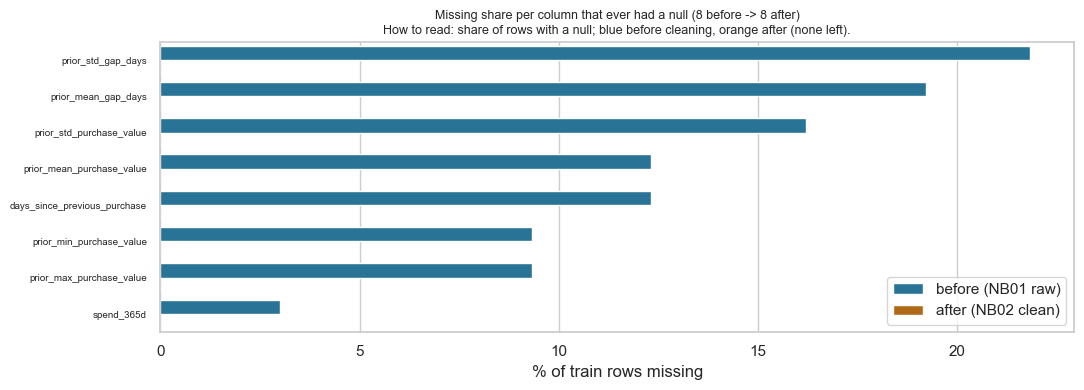

=== Summary ===
  columns with nulls before : 8
  columns with nulls after  : 8 -> ['prior_std_gap_days', 'prior_mean_gap_days', 'prior_std_purchase_value', 'prior_mean_purchase_value', 'days_since_previous_purchase', 'prior_min_purchase_value', 'prior_max_purchase_value', 'spend_365d']
  missing cells before      : 7,478
  missing cells after       : 0
  new flag columns added    : 12


In [14]:
# CELL 14 - Before/after missingness check for every column that ever had a null.
raw = pd.read_csv(DATA_DIR / "train_raw.csv")
raw = raw.loc[~raw[transaction_cols].isna().all(axis=1)]
before = raw.isna().sum()
before = before[before > 0].sort_values(ascending=False) / len(raw) * 100
# keep every column that was missing before, at 0% if it is now clean - the point of the figure is
# the pair of bars, and dropping the zero bars would hide what the cleaning actually achieved.
shown = [c for c in before.index if c in train_model.columns]
before = before[shown]
after = train_model[shown].isna().sum() / len(train_model) * 100

long = pd.concat([
    pd.DataFrame({"column": before.index, "pct_missing": before.values, "stage": "before (NB01 raw)"}),
    pd.DataFrame({"column": after.index, "pct_missing": after.values, "stage": "after (NB02 clean)"}),
], ignore_index=True)

fig, ax = plt.subplots(figsize=(11, 1.5 + 0.32 * len(before)))
sns.barplot(data=long, y="column", x="pct_missing", hue="stage", orient="h",
            palette=[PLOT_BLUE, PLOT_ORANGE], ax=ax)
ax.set_title("Missing share per column that ever had a null ({} before -> {} after)".format(
    len(before), len(after)))
ax.set_xlabel("% of train rows missing")
ax.set_ylabel("")
plt.setp(ax.get_yticklabels(), fontsize=7)
ax.legend()
guide(ax, "How to read: share of rows with a null; blue before cleaning, orange after (none left).")
plt.tight_layout()
plt.savefig(FIG_DIR / "nb02_missing_before_after.png", dpi=200)
plt.show()

print("=== Summary ===")
print("  columns with nulls before :", len(before))
print("  columns with nulls after  :", len(after), "->", list(after.index) if len(after) else "none")
print("  missing cells before      : {:,}".format(int(raw.isna().sum().sum())))
print("  missing cells after       : {:,}".format(int(train_model[feature_cols].isna().sum().sum())))
print("  new flag columns added    : {:,}".format(len(flag_cols)))

### Cell 15 - Persist
**Purpose.** Write everything downstream needs, as CSV.
**Method.** Clean matrices, the feature list with a role for every column, the fitted parameters, and
the cleaning log. No pickle anywhere.
**Look at.** The file list: `preprocessing_params.csv` is what makes the transformation auditable
without an object file.

In [15]:
# CELL 15 - Persist everything the next notebooks need. CSV only, no pickle.
train_model.to_csv(DATA_DIR / "train_clean.csv", index=False)
test_model.to_csv(DATA_DIR / "test_clean.csv", index=False)

feature_lists = pd.concat([
    pd.DataFrame({"feature": scale_cols, "kind": "numeric_scaled"}),
    pd.DataFrame({"feature": flag_cols, "kind": "indicator_flag"}),
    pd.DataFrame({"feature": names, "kind": "one_hot"}),
    pd.DataFrame({"feature": ["ID", "customer_id"], "kind": ["identifier", "identifier"]}),
    pd.DataFrame({"feature": [TARGET], "kind": ["target"]}),
    pd.DataFrame({"feature": ["purchase_year", "random_noise"] + meta_drop,
                  "kind": ["excluded_qa", "excluded_noise"] + ["excluded_metadata"] * len(meta_drop)}),
], ignore_index=True)
feature_lists.to_csv(DATA_DIR / "feature_lists.csv", index=False)

params.to_csv(FEAT_DIR / "preprocessing_params.csv", index=False)
medians.to_csv(FEAT_DIR / "imputation_medians.csv", index=False)
pd.DataFrame({"column": ENC_COLS, "categories": [", ".join(map(str, c)) for c in enc.categories_]}
             ).to_csv(FEAT_DIR / "encoder_categories.csv", index=False)
pd.DataFrame([{"column": c, "kept_levels": len(k), "grouped_into_other": "yes"}
              for c, k in kept_levels.items()]).to_csv(FEAT_DIR / "categorical_levels.csv", index=False)

log_df = pd.DataFrame(CLEAN_LOG)
log_df.to_csv(LOG_DIR / "cleaning_log.csv", index=False)
print("=== Cleaning log (the full column lists are in artifacts/logs/cleaning_log.csv) ===")
print(log_df[["step", "action", "rows_affected", "reason"]].to_string(index=False))
print("\nSaved:")
print("  data/train_clean.csv, data/test_clean.csv, data/feature_lists.csv")
print("  artifacts/features/: preprocessing_params, imputation_medians, encoder_categories, categorical_levels")
print("  artifacts/logs/cleaning_log.csv, artifacts/figures/nb02_missing_before_after.png")

=== Cleaning log (the full column lists are in artifacts/logs/cleaning_log.csv) ===
             step                                                                   action  rows_affected                                                                        reason
             load                        read train_raw / test_raw / clientes_raw from CSV           7520                                      Notebook 01 hands over raw frames as CSV
            roles                                                drop planted noise column              0                           NB01 Cell 13: near-zero association with the target
            roles                                  drop non-analysable clientes attributes              0             free text / near-unique identifiers / fully empty (customer_type)
       empty rows                         drop train rows with all transaction fields null             65                              no information left to impute; balance unchan

### Cell 16 - Handover
**Purpose.** Summarise what changed and what Notebook 03 receives.
**Look at.** The final feature count and the reminder that every estimator here was fitted on train
rows only.

In [16]:
# CELL 16 - Handover summary for Notebook 03.
print("=== Notebook 02 complete ===")
print("  train rows / test rows   : {} / {}".format(len(train_model), len(test_model)))
print("  modelled features        : {} ({} numeric, {} flags, {} one-hot)".format(
    len(feature_cols), len(scale_cols), len(flag_cols), len(names)))
print("  target positive rate     : {:.4f}  (NB01: 0.5592 before the 65 empty rows were dropped)".format(
    float(train_model[TARGET].mean())))
print("  fitted on train only     : imputer, scaler, encoder")
print("  reproducibility records  : artifacts/features/*.csv and artifacts/logs/cleaning_log.csv")
print("\nNotebook 03 receives data/train_clean.csv and data/test_clean.csv and runs the feature-")
print("selection strategy: variance filter, L1-regularised logistic regression, and a decision-")
print("tree importance screen - all fitted on the training rows only.")

=== Notebook 02 complete ===
  train rows / test rows   : 6469 / 986
  modelled features        : 124 (30 numeric, 12 flags, 82 one-hot)
  target positive rate     : 0.5597  (NB01: 0.5592 before the 65 empty rows were dropped)
  fitted on train only     : imputer, scaler, encoder
  reproducibility records  : artifacts/features/*.csv and artifacts/logs/cleaning_log.csv

Notebook 03 receives data/train_clean.csv and data/test_clean.csv and runs the feature-
selection strategy: variance filter, L1-regularised logistic regression, and a decision-
tree importance screen - all fitted on the training rows only.


---

## Where this notebook leaves the project

**Produced.** `data/train_clean.csv` (6,469 rows), `data/test_clean.csv` (986 rows),
`data/feature_lists.csv`, the fitted parameters in `artifacts/features/`, and the full cleaning
record in `artifacts/logs/cleaning_log.csv`.

**What changed from the raw data.** 65 empty train rows removed; sentinels and impossible negatives
turned into NaN plus flags; structural history nulls set to 0 with flags; `clientes` joined 1:1;
categorical nulls given an explicit `Missing` level and rare levels grouped into `Other`; medians
fitted on train only; `log1p` on the skewed columns; `purchase_month` and two ratios added;
`purchase_year` computed but excluded; everything numeric standardised and everything nominal
one-hot encoded on train categories only.

**Next: Notebook 03 - Feature Selection.** It takes the 124 modelled columns and runs the five
stage funnel, comparing candidate sets by measured cross-validated F1 rather than by choice.